# Clasificación de Rock y Hip-Hop mediante características de audio

**Hector Americo Torres Huamani** · [Repositorio](https://github.com/hectortorres26/clasificacion-generos-musicales)

## 1. Contexto y objetivo

Clasificar pistas de Rock y Hip-Hop a partir de ocho características acústicas. El objetivo es evaluar una clasificación reproducible que tenga en cuenta el desequilibrio de clases, con una prueba independiente de la selección del modelo.

## 2. Datos y reproducibilidad

Origen del proyecto: [Free Music Archive (FMA)](https://github.com/mdeff/fma). Para esta ejecución se usó la [copia pública del material de DataCamp](https://github.com/veeralakrishna/DataCamp-Project-Solutions-Python/tree/master/Classify%20Song%20Genres%20from%20Audio%20Data/datasets). Descarga `fma-rock-vs-hiphop.csv`, renómbralo `songs.csv` y descarga `echonest-metrics.json`; coloca ambos en `data/`. La copia consultada contiene 17.734 filas de pistas y 13.129 filas de métricas, antes de la unión y el filtro.

Los resultados publicados se ejecutaron con copias públicas descargadas de las fuentes indicadas. No se ha verificado identidad byte a byte con los archivos del Drive del autor. Las huellas SHA-256 en [data/README.md](data/README.md) y `reports/metrics.json` identifican las entradas exactas. Los datasets se excluyen de Git; consulta las condiciones de cada fuente antes de reutilizarlos o redistribuirlos.

| Campo | Uso |
|---|---|
| `track_id` | Clave de unión; nunca predictor |
| `genre_top` | Etiqueta objetivo: Rock o Hip-Hop |
| `acousticness`, `instrumentalness` | Características acústicas e instrumentales |
| `danceability`, `energy`, `valence` | Descriptores musicales |
| `liveness`, `speechiness`, `tempo` | Descriptores de directo, voz hablada y tempo |

Los ocho predictores se utilizan como mediciones provistas por Echonest; este proyecto no extrae características directamente de archivos de audio.

Ejecuta desde la raíz del repositorio con el entorno de `requirements.txt`. El código de análisis reside en `src/analysis.py`, para que el cuaderno y la línea de comandos utilicen el mismo procedimiento.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import Image, display
from src.analysis import run

ROOT = Path.cwd()
assert (ROOT / 'src/analysis.py').exists(), 'Abre el cuaderno desde la raíz del repositorio.'

## 3. Diseño del análisis

1. Validar los dos archivos y unirlos por `track_id` con relación uno a uno. Rechazar identificadores duplicados, infinitos y características completamente ausentes. Comprobar duplicados exactos de las ocho características.
2. Conservar 4.802 pistas: 3.892 Rock y 910 Hip-Hop. Reservar el 25 % mediante una división estratificada, con semilla 42.
3. Ajustar imputación por mediana, `StandardScaler` y PCA (95 % de varianza) dentro de cada pipeline y de cada partición de entrenamiento.
4. Comparar referencia mayoritaria, árbol con pesos balanceados y regresión logística con pesos balanceados mediante cinco particiones estratificadas del entrenamiento. Los hiperparámetros están fijados en el código; no se afirma una búsqueda exhaustiva.
5. Seleccionar por F1 macro medio de validación y evaluar el modelo seleccionado y la referencia en el mismo conjunto de prueba. No equilibrar artificialmente la prueba.
6. Estimar un intervalo de F1 macro con 500 remuestreos de las predicciones de prueba, manteniendo el modelo fijo.

In [2]:
resultado = run(ROOT / 'data/songs.csv', ROOT / 'data/echonest-metrics.json', ROOT / 'reports')

## 4. Resultados calculados

Las tablas siguientes proceden de esta ejecución. Las métricas comparativas utilizan una prueba reservada cuando el proyecto entrena modelos.

In [3]:
display(pd.DataFrame({nombre: {k: v for k, v in resultado[clave].items() if isinstance(v, (float, int))} for nombre, clave in [('Modelo', 'test'), ('Referencia', 'baseline_test')]}))

,Modelo,Referencia
accuracy,0.846794,0.810158
balanced_accuracy,0.838283,0.500000
f1_macro,0.785769,0.447562


### Validacion cruzada

In [4]:
display(pd.read_csv(ROOT / 'reports/validacion_cruzada.csv'))

,modelo,f1_macro_media,f1_macro_desviacion,balanced_accuracy_media
0,base_mayoritaria,0.447699,0.000212,0.500000
1,arbol_balanceado,0.801943,0.012035,0.840778
2,regresion_logistica,0.818986,0.008045,0.860324


### Clasificacion

In [5]:
display(pd.read_csv(ROOT / 'reports/clasificacion.csv'))

,clase,precision,recall,f1-score,support
0,Hip-Hop,0.566265,0.824561,0.671429,228.0
1,Rock,0.953970,0.852004,0.900109,973.0
2,macro avg,0.760118,0.838283,0.785769,1201.0
3,weighted avg,0.880367,0.846794,0.856696,1201.0


## 5. Visualización e interpretación

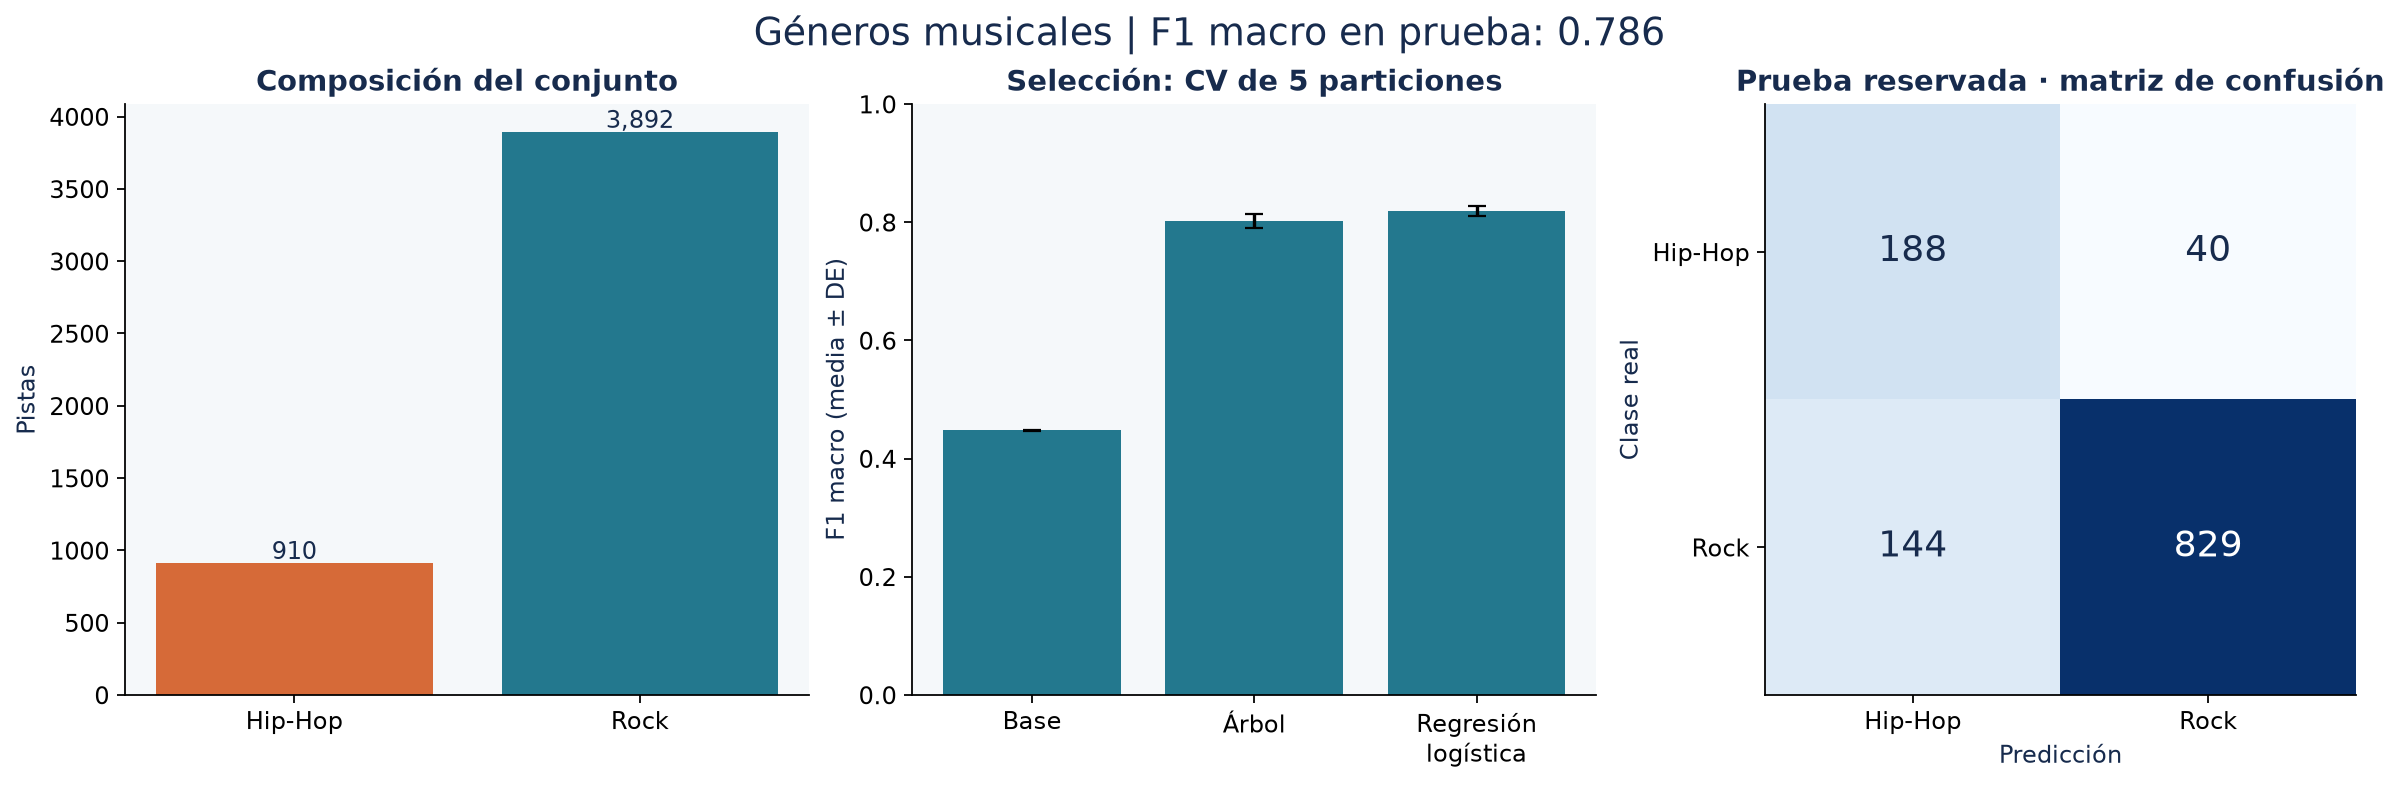

In [6]:
display(Image(filename=str(ROOT / 'reports/evaluacion.png')))

La exactitud aislada ocultaría el fallo de la referencia, que predice siempre Rock. F1 macro pondera por igual ambos géneros. La regresión logística detecta 188 de las 228 pistas Hip-Hop de prueba, pero también etiqueta como Hip-Hop 144 pistas Rock: la precisión de Hip-Hop es 56,63 %. Este coste debe considerarse antes de usar el clasificador para etiquetar un catálogo.

## 6. Limitaciones y próximos pasos

Solo se cubren dos géneros y una colección concreta. La división es por pista: no garantiza separación por artista o álbum porque esos identificadores no forman parte de las entradas utilizadas. El intervalo bootstrap no incorpora incertidumbre del entrenamiento y puede ser optimista si las pistas están relacionadas. No se ha validado audio nuevo, otros géneros ni cambios de distribución. Las métricas antiguas no son directamente comparables porque cambió el protocolo de evaluación; no se afirma haber eliminado todo sesgo.

Antes de ampliar el uso, validar con una fuente independiente y acordar criterios de utilidad con el destinatario. Consulta el README para reproducir las pruebas y los informes.

## 7. Trazabilidad de esta ejecución

Se muestran nombres de archivos, huellas SHA-256 y versiones; las entradas completas permanecen fuera de Git.

In [7]:
fuentes = resultado.get('fuentes', [resultado.get('fuente')])
print(json.dumps(fuentes, ensure_ascii=False, indent=2))

[
  {
    "archivo": "songs.csv",
    "sha256": "3a2fee2daeb68bb387a8c3f306e6a26799c8b9c6a2ab7b74a83d7144dbd8747d",
    "python": "3.11.9",
    "paquetes": {
      "pandas": "3.0.6",
      "numpy": "2.4.6",
      "matplotlib": "3.11.2",
      "scikit-learn": "1.9.1"
    }
  },
  {
    "archivo": "echonest-metrics.json",
    "sha256": "a1b8837781dfde332a1ae99a7f11cb29e2fa976c4b6821bd66af5b83fa201719",
    "python": "3.11.9",
    "paquetes": {
      "pandas": "3.0.6",
      "numpy": "2.4.6",
      "matplotlib": "3.11.2",
      "scikit-learn": "1.9.1"
    }
  }
]


[Historial del proyecto](https://github.com/hectortorres26/clasificacion-generos-musicales/commits/main) · [Comparación con el original](https://github.com/hectortorres26/clasificacion-generos-musicales/compare/4dffafd3f5e8f511ca13eded6ec59a2362b12e84...main)